# Online Retail: historical behavior and future-spending target

Business question: which existing customers will make no purchase, regular purchases or high-value purchases during the next 91 days? These tiers can help prioritize retention and account management; they are a finite-horizon CLTV proxy, not lifetime revenue or causal marketing uplift.

No original project files were present. This notebook uses [UCI Online Retail](https://archive.ics.uci.edu/dataset/352/online-retail), Chen (2015), DOI 10.24432/C5BW33, CC BY 4.0. It describes a UK online retailer, including wholesale customers. All figures are computed from the downloaded workbook.

Historical features use **2010-12-01 <= time < 2011-09-01**. The target uses **2011-09-01 <= time < 2011-12-01**. Partial December 2011 is excluded. This notebook describes historical transactions and training outcomes only; no test-target EDA is used to choose features or tune the model.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / "scripts").is_dir() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
sns.set_theme(style="whitegrid", palette="colorblind")
FIGURES = ROOT / "results/figures"
FIGURES.mkdir(parents=True, exist_ok=True)

In [2]:
audit = json.loads((ROOT / "results/data_audit.json").read_text())
transactions = pd.read_csv(ROOT / "data/processed/transactions.csv", parse_dates=["InvoiceDate"])
customers = pd.read_csv(ROOT / "data/processed/customers.csv", index_col="CustomerID")
history = transactions.loc[transactions.InvoiceDate < pd.Timestamp("2011-09-01")].copy()
train = customers.loc[customers.split == "train"]
display(pd.Series({key: audit[key] for key in
    ["raw_rows", "raw_customers", "clean_rows", "clean_customers", "clean_invoices",
     "observation_rows", "observation_invoices", "eligible_customers", "no_future_purchase_customers"]},
    name="actual_count").to_frame())
display(pd.Series(audit["removed_rows_sequential"], name="rows_removed_in_order").to_frame())

,actual_count
raw_rows,541909
raw_customers,4372
clean_rows,392692
clean_customers,4338
clean_invoices,18532
observation_rows,224036
observation_invoices,11413
eligible_customers,3317
no_future_purchase_customers,1446


,rows_removed_in_order
missing_customer_id,135080
duplicate_rows,5225
cancelled_invoices,8872
nonpositive_quantity,0
nonpositive_price,40
invalid_date,0


Cleaning removes missing customer IDs, exact duplicate rows, cancellations, nonpositive quantities/prices and invalid dates in that order. Counts are sequential and reconcile to the raw workbook. Duplicate line removal assumes exact repeats are accidental; the source cannot prove this. Missing descriptions do not invalidate an otherwise usable purchase. Positive postage/service lines and genuine extreme purchases are retained. Revenue is quantity × price (GBP); refunds are excluded, so this is gross positive purchase revenue.

In [3]:
display(history[["Quantity", "UnitPrice", "revenue"]].describe(percentiles=[.5, .9, .99]).T)
display(train[["recency_days", "frequency", "monetary", "tenure_days", "mean_gap_days"]]
        .describe(percentiles=[.5, .9, .99]).T)

,count,mean,std,min,50%,90%,99%,max
Quantity,224036.0,13.676851,163.301661,1.000,6.00,24.00,144.00,74215.00
UnitPrice,224036.0,3.197599,21.884709,0.001,1.95,6.95,14.95,8142.75
revenue,224036.0,23.333215,197.290826,0.001,12.75,38.25,207.50,77183.60


,count,mean,std,min,50%,90%,99%,max
recency_days,2653.0,93.890691,77.913155,0.280556,72.574306,215.417083,272.499222,273.557639
frequency,2653.0,3.460611,5.756337,1.000000,2.000000,7.000000,23.000000,127.000000
monetary,2653.0,1473.682960,5240.799953,2.900000,539.170000,2766.242000,13875.929600,176355.940000
tenure_days,2653.0,177.753692,77.446440,0.283333,187.466667,268.512500,273.497778,273.648611
mean_gap_days,1553.0,58.107658,45.711918,0.000000,45.297222,116.941528,224.009361,259.955556


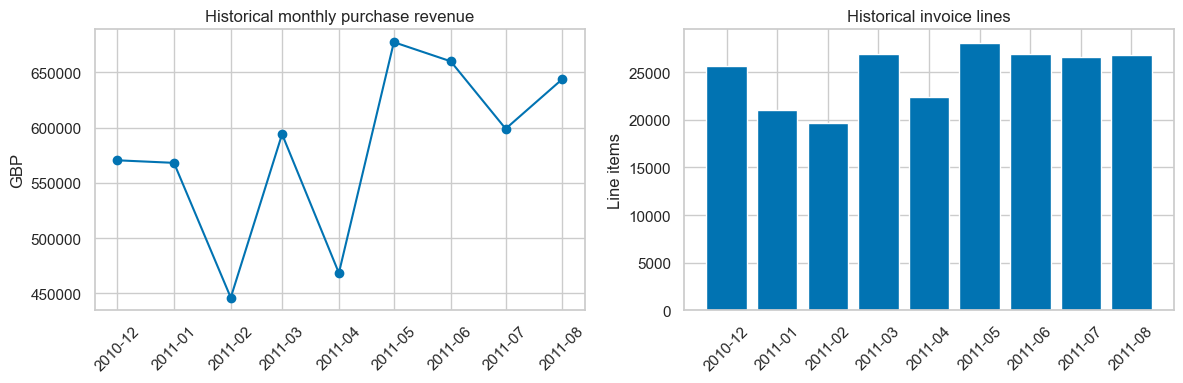

In [4]:
monthly = history.set_index("InvoiceDate").resample("MS").agg(
    revenue=("revenue", "sum"), line_items=("InvoiceNo", "size"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(monthly.index, monthly.revenue, marker="o")
axes[0].set(title="Historical monthly purchase revenue", ylabel="GBP")
axes[1].bar(monthly.index.strftime("%Y-%m"), monthly.line_items)
axes[1].set(title="Historical invoice lines", ylabel="Line items")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
fig.savefig(FIGURES / "monthly_history.png", dpi=150)
plt.show()

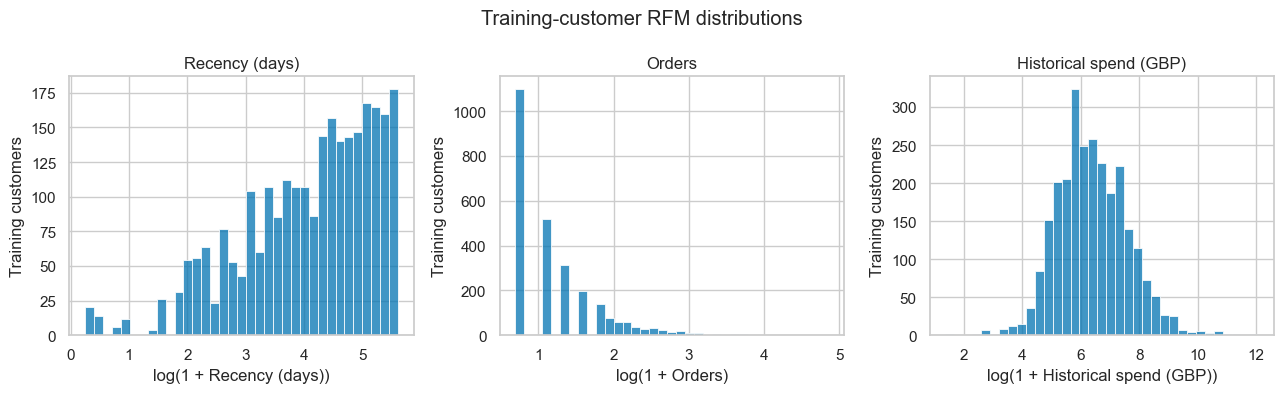

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, column, title in zip(axes, ["recency_days", "frequency", "monetary"],
                             ["Recency (days)", "Orders", "Historical spend (GBP)"]):
    sns.histplot(np.log1p(train[column]), bins=35, ax=ax)
    ax.set(xlabel=f"log(1 + {title})", title=title, ylabel="Training customers")
fig.suptitle("Training-customer RFM distributions")
fig.tight_layout()
fig.savefig(FIGURES / "rfm_distributions.png", dpi=150)
plt.show()

RFM summarizes how recently a customer bought, how many distinct invoices they placed, and their historical purchase value. Heavy tails motivate log1p scaling for PCA/K-Means. Single-order customers have undefined inter-order cadence; the training pipeline imputes these fields and includes a single-order indicator. First-observed tenure is left-censored by the dataset start.

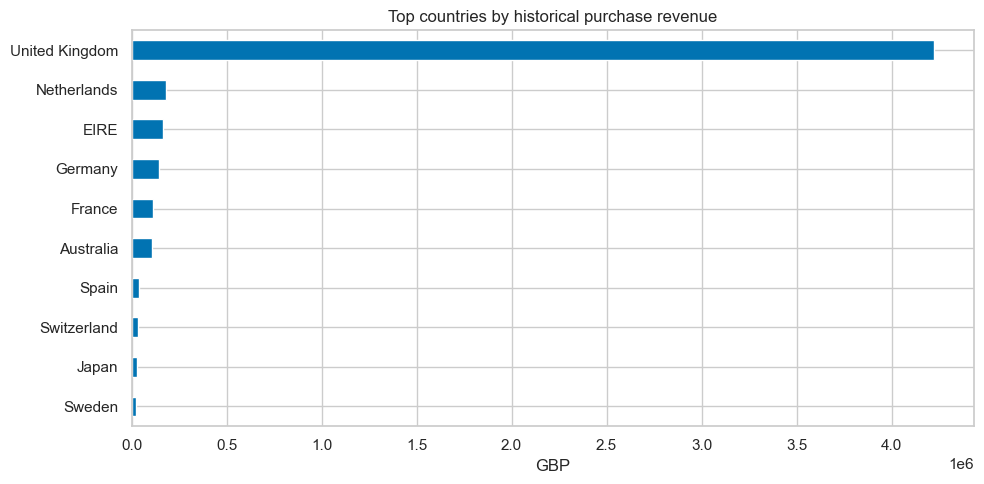

In [6]:
fig, ax = plt.subplots(figsize=(10, 5))
top_countries = history.groupby("Country").revenue.sum().nlargest(10).sort_values()
top_countries.plot.barh(ax=ax)
ax.set(title="Top countries by historical purchase revenue", xlabel="GBP", ylabel="")
fig.tight_layout()
fig.savefig(FIGURES / "country_revenue.png", dpi=150)
plt.show()

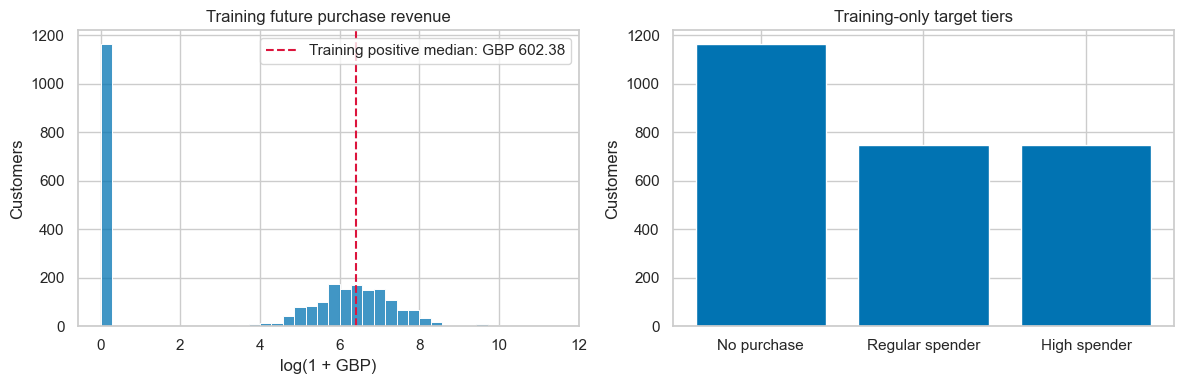

Training positive-spend median: **GBP 602.38**. Training customers: **2,653**; held-out customers: **664**.

In [7]:
boundary = train.loc[train.future_spend > 0, "future_spend"].median()
labels = np.where(train.future_spend <= 0, 0, np.where(train.future_spend <= boundary, 1, 2))
tier_names = ["No purchase", "Regular spender", "High spender"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(np.log1p(train.future_spend), bins=40, ax=axes[0])
axes[0].axvline(np.log1p(boundary), color="crimson", linestyle="--",
               label=f"Training positive median: GBP {boundary:.2f}")
axes[0].set(title="Training future purchase revenue", xlabel="log(1 + GBP)", ylabel="Customers")
axes[0].legend()
counts = pd.Series(labels).value_counts().reindex([0, 1, 2], fill_value=0)
axes[1].bar(tier_names, counts)
axes[1].set(title="Training-only target tiers", ylabel="Customers")
fig.tight_layout()
fig.savefig(FIGURES / "training_target_tiers.png", dpi=150)
plt.show()
display(Markdown(f"Training positive-spend median: **GBP {boundary:.2f}**. "
                 f"Training customers: **{len(train):,}**; held-out customers: "
                 f"**{customers.split.eq('test').sum():,}**."))

Zero future spending is a meaningful retention outcome and is kept as its own class. Positive future spend is split at the training-only median. In five-fold CV, this median is learned again inside each fold's training set; validation spending never calibrates its own labels.

The split is customer-disjoint at a single prediction date. It tests generalization to other existing customers, not to a later calendar period. New customers first seen in the target window cannot have historical features and are excluded. No historical >85% accuracy is assumed.